# Web APIs 第七天实战：小兔鲜商品详情页

## 0. 本次实战与工程准备

本次用一个商品详情页，综合练习 Web APIs 阶段的事件、事件委托、DOM 样式、排他选择、定时器、页面滚动和元素位置。按原《个人实战文档》的顺序，先完成顶部导航、图片切换和放大镜，再选做规格点击、详情 Tab 和返回顶部。

资料来自[课程分享](https://pan.baidu.com/s/1MxueOHXGQtmE-ypRq1kELA?pwd=9987)（提取码 `9987`）中的 `1. Pink最新版前端JavaScript / 2.web APIs / 资料 / web APIs第七天实战`。已完整读取原实战 Markdown、`code/素材/product-dev.html`、`效果/product-dev.html` 以及配套折叠菜单练习。原文参考效果地址为 `http://erabbit.itheima.net/#/product/3995139`，这里只保留课程给出的地址，不把旧在线站点作为运行前提。

本文的主要 JavaScript 摘录自网盘**效果目录的成品源码**；原文“放大镜完整代码”标题后没有代码，不能把成品脚本说成讲义中的代码。网页高亮预览中的不换行空格恢复为普通空格，保留变量、注释和语句。图片来自原实战文档的 `assets/555.gif`。

配套样式与静态结构还对照了[同课公开素材副本](https://github.com/wukaihang/pink-javascript/tree/main/2.Web%20APIs/day7)。下文引用副本 CSS 时单独注明；为说明结构、修正坐标或完成选做需求而整理的内容也单独标注。

### 0.1 从静态素材开始，先认清页面结构

在资料的 `code/素材` 目录打开 `product-dev.html`，相对目录 `css`、`images`、`uploads` 应一起保留。原静态文件没有 JavaScript；成品则在页面末尾、DOM 结构之后增加脚本。不能直接把成品脚本放进静态文件而忽略新增的 `.sticky`、规格 ID 和 Tab 属性，否则选择器会取不到节点，或找不到对应面板。

| 区域 | 选择器 | 本篇要做的事 |
| --- | --- | --- |
| 黑色账户栏 | `.xtx_topnav` | 原有静态区，不是后加的滑出导航 |
| 原主导航 | `.xtx_header .wrapper` | 作为滚动阈值的参照物 |
| 新滑出导航 | `.sticky` | 固定在视口顶部，用 `top` 控制进出 |
| 商品图区域 | `.pictrue` | 原类名就是这个拼写，代码保持一致 |
| 中图、遮罩 | `.middle`、`.layer` | 显示当前图片并确定选中的局部 |
| 小图、大图 | `.small`、`.large` | 切换图片，并用背景图显示放大区域 |
| 两组规格 | `.item #color`、`.item #size` | 各自在组内保留一个 `active` |
| 商品介绍 | `.tab-head`、`.tab-pane` | 切换详情和评价 |

成品的几个功能放在各自的立即执行函数中，避免不同模块的 `const`、`let` 重名。本篇把“三个图的故事”按步骤摘录；这些片段属于**同一个函数作用域**，按顺序放在一起，而不是给每个片段另套一个函数。

整理示意：把第 2 节和第 3 节的四段原脚本放进下面这个模块；其他模块保留各自原有的立即执行函数。

```javascript
;(function () {
  // 依次放入：获取三盒与图片切换、放大图显隐、遮罩显隐、mousemove。
})();
```

## 1. 顶部导航模块

### 1.1 需求：主导航离开视口后，新导航从顶部滑出

页面初始隐藏新导航。当页面向下滚动到主导航下边缘时，显示固定导航；滚回阈值上方，再把它收回去。

先在 `.xtx_header` 后加入成品的 `.sticky` 结构。下面是**按成品类名整理的最小结构示意**，导航内容在原成品中还包括首页、居家、美食等链接，实际制作时保留完整结构和样式。

```html
<div class="sticky">
  <div class="header-sticky container">
    <div class="sticky-logo"><h1><a href="#"></a></h1></div>
    <ul class="sticky-nav">
      <li><a href="#">首页</a></li>
      <li><a href="#">居家</a></li>
    </ul>
    <div class="sticky-right">
      <a href="#">品牌</a>
      <a href="#">专题</a>
    </div>
  </div>
</div>
```

成品 head 中引用 `fonts/iconfont.css`、`css/index.css`、`css/common.css`、`css/product.css`；仅从静态素材开始时，要一起迁入新导航所需资源。`top` 的改变需要 CSS 配合：固定定位、初始藏到视口上方、预留层级和过渡。

以下是**解释运动所需的最小补充 CSS**，不是对未读取成品 CSS 的逐字引用；完整外观继续使用成品资源。

```css
.sticky {
  position: fixed;
  left: 0;
  top: -80px;
  width: 100%;
  height: 80px;
  z-index: 1000;
  background: #fff;
  transition: top 0.3s;
}
```

### 1.2 用主导航的下边缘计算滚动阈值

原成品脚本：

```javascript
    //顶部导航栏自动滑出
    (function () {
      const sticky = document.querySelector('.sticky');
      const header = document.querySelector('.xtx_header .wrapper');
      const headerTop = header.offsetTop;
      const heaerHeight = header.clientHeight;
      const top = headerTop + heaerHeight;
      window.addEventListener('scroll', function () {
        const n = document.documentElement.scrollTop;
        if (n >= top) {
          sticky.style.top = '0px';
        } else {
          sticky.style.top = '-80px';
        }
      })
    })();
```

`headerTop + heaerHeight` 表示主导航下边缘相对页面的位置。原变量 `heaerHeight` 拼写如此，这里保留。当前主导航的布局使 `offsetTop` 可用于这个页面阈值；它的一般含义仍是相对定位参照父级的偏移，不能对任意嵌套布局都当作页面坐标。

`scrollTop >= top` 时把新导航设为 `top: 0px`；小于阈值时设为 `-80px`。这里的 `-80px` 与导航高度配套。原 HTML 注释说“添加 show 类名可以显示”，但实际脚本直接改 `style.top`，本篇以脚本行为为准。

原代码只在 `scroll` 发生时判断。刷新后浏览器恢复到页面中部，如果没有触发滚动，初始状态可能还没同步；需要完善时，可以把判断提取为函数，并在绑定后调用一次。这属于初始化补充，不改变课程的阈值思路。

验证时缓慢跨过主导航底部，再滚回去：新导航应分别进入和退出视口。它是另一个固定元素，原主导航仍保留在文档中。

## 2. 图片切换模块

### 2.1 先准备中图、缩略图和背景大图

下面是素材 `product-dev.html` 中的原结构摘录，已与网盘静态结构核对；首个 `li` 默认带 `active`。

```html
          <div class="pictrue">
            <div class="middle">
              <img src="./images/1.jpg" alt="">
              <div class="layer"></div>
            </div>
            <div class="small">
              <ul>
                <li class="active"><img src="./images/1.jpg" alt=""></li>
                <li><img src="./images/2.jpg" alt=""></li>
                <li><img src="./images/3.jpg" alt=""></li>
                <li><img src="./images/4.jpg" alt=""></li>
                <li><img src="./images/5.jpg" alt=""></li>
              </ul>
            </div>
            <div class="large"></div>
          </div>
```

中图是 `img`，右侧大图则是空的 `.large` 盒子，通过 CSS 背景显示。因此换图时要分别更新 `img.src` 和 `backgroundImage`。

需要保留的尺寸与样式关系如下。规则取自同课公开素材的 `css/product.css`，这里只摘录与三图相关的部分：

```css
.xtx-product-info .left .pictrue {
  width: 480px;
  height: 400px;
  display: flex;
  position: relative;
}

.xtx-product-info .left .pictrue .middle {
  width: 400px;
  height: 400px;
  position: relative;
}

.xtx-product-info .left .pictrue .middle .layer {
  display: none;
  width: 200px;
  height: 200px;
  background-color: rgba(0, 0, 0, 0.3);
  position: absolute;
  left: 0;
  top: 0;
  cursor: move;
}

.xtx-product-info .left .pictrue .large {
  width: 400px;
  height: 400px;
  box-shadow: 0 0 10px rgba(0, 0, 0, 0.2);
  position: absolute;
  left: 412px;
  top: 0;
  z-index: 999;
  background-color: #fff;
  display: none;
  background-image: url(../images/1.jpg);
  background-size: 800px 800px;
}

.xtx-product-info .left .pictrue .middle img {
  width: 100%;
  height: 100%;
}

.xtx-product-info .left .pictrue .small {
  width: 80px;
  height: 400px;
}

.xtx-product-info .left .pictrue .small ul li {
  width: 68px;
  height: 68px;
  margin-bottom: 15px;
  margin-left: 12px;
  border: 2px solid transparent;
}

.xtx-product-info .left .pictrue .small ul li img {
  width: 100%;
  height: 100%;
}

.xtx-product-info .left .pictrue .small ul li.active,
.xtx-product-info .left .pictrue .small ul li:hover {
  border-color: #27BA9B;
}
```

首张大图背景在 CSS 中默认指向 `images/1.jpg`，与中图初始图片一致。否则刚进入中图、还没经过缩略图时，大图会是空的。

### 2.2 在小图容器上用 mouseover 做事件委托

原成品“三个图的故事”模块的第一段代码如下；接下来第 3 节的三个片段继续放在它后面，处于同一作用域。

```javascript
      // 1. 获取三个盒子
      // 2. 小盒子 图片切换效果
      const small = document.querySelector('.small')
      //  中盒子
      const middle = document.querySelector('.middle')
      //  大盒子
      const large = document.querySelector('.large')
      // 2. 事件委托
      small.addEventListener('mouseover', function (e) {
        if (e.target.tagName === 'IMG') {
          // console.log(111)
          // 排他 干掉以前的 active  li 上面
          this.querySelector('.active').classList.remove('active')
          // 当前元素的爸爸添加 active
          e.target.parentNode.classList.add('active')
          // 拿到当前小图片的 src
          // console.log(e.target.src)
          // 让中等盒子里面的图片，src 更换为   小图片src
          middle.querySelector('img').src = e.target.src
          // 大盒子更换背景图片
          large.style.backgroundImage = `url(${e.target.src})`
        }
      })
```

把监听器绑给 `.small`，让内部图片的 `mouseover` 冒泡到容器；用 `e.target.tagName === 'IMG'` 排除经过空白或列表边缘的情况。这里需要冒泡，所以原文选择 `mouseover`，不能直接换成不冒泡的 `mouseenter` 继续做同样的委托。

每次真正经过一张图片时，按顺序做四件事：

1. 删除当前小图列表里旧 `li` 的 `active`。
2. 给目标图片的父节点 `li` 加 `active`。
3. 将目标图片的 `src` 赋给中图。
4. 将同一地址设为大图背景。

`this` 是绑定事件的 `.small`；`e.target` 是实际经过的 `img`。高亮属于 `li`，所以使用 `e.target.parentNode`。此处直接调用旧 `.active` 的 `classList`，依赖 HTML 中至少有一个初始选中项；如果把默认 `active` 删除，就需要先判空。

验证：依次经过五张缩略图，列表始终只有一个选中项，中图和大图始终指向同一张图片。

## 3. 放大镜效果

### 3.1 把四步业务和尺寸关系对应起来

原文把功能分成四步：小图切换中图；进入中图显示大图；遮罩跟随鼠标；大背景图显示遮罩对应的区域。第 2 节已完成第一步，下面依次完成后三步。

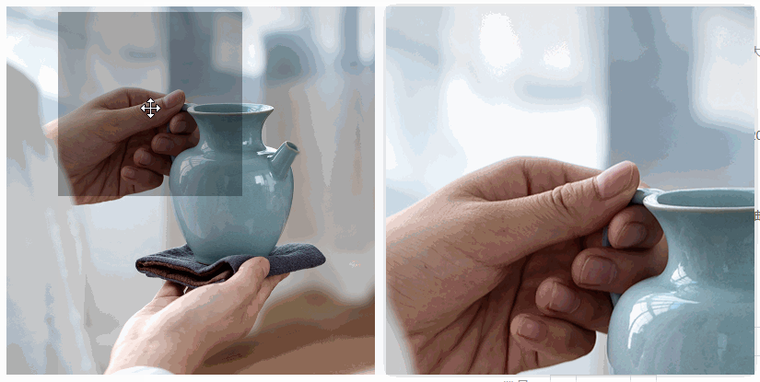

图片取自原 `assets/555.gif` 的第 10 帧并裁切。中图上的半透明方块表示当前查看范围，右侧窗口显示这个范围的放大内容。

| 元素或图像 | 尺寸 | 作用 |
| --- | --- | --- |
| 中图 `.middle` | 400 × 400px | 鼠标活动的图像区域 |
| 遮罩 `.layer` | 200 × 200px | 选中中图的一块局部 |
| 大图可见窗口 `.large` | 400 × 400px | 显示放大后的局部 |
| 大背景图 | 800 × 800px | 中图以 2 倍比例呈现后的完整图像 |

遮罩选中的 200px 对应大图窗口中的 400px，因此背景移动距离也应是遮罩移动距离的 2 倍。这些数值配套使用；修改任意一个尺寸后，原代码中的 `100`、`200`、`300`、`400` 和倍率 `2` 也要重新对应。

### 3.2 中图和大图共用显示、延迟隐藏逻辑

原成品片段，接在第 2 节的图片切换代码之后：

```javascript
      // 3. 鼠标经过中等盒子， 显示隐藏 大盒子
      middle.addEventListener('mouseenter', show)
      middle.addEventListener('mouseleave', hide)
      let timeId = null
      // 显示函数 显示大盒子
      function show() {
        // 先清除定时器
        clearTimeout(timeId)
        large.style.display = 'block'
      }
      // 隐藏函数 隐藏大盒子
      function hide() {
        timeId = setTimeout(function () {
          large.style.display = 'none'
        }, 200)
      }


      // 4. 鼠标经过大盒子， 显示隐藏 大盒子
      large.addEventListener('mouseenter', show)
      large.addEventListener('mouseleave', hide)
```

进入中图调用 `show()`，显示大图；离开中图调用 `hide()`，在 **200ms 后**隐藏。不能离开中图立即隐藏：中图与右侧大图之间有一小段间隔，鼠标需要时间跨过去。

大图也绑定相同的 `mouseenter`、`mouseleave`。在 200ms 内进入大图，`show()` 先 `clearTimeout(timeId)`，取消上一轮隐藏计划，于是鼠标停留在大图上时窗口继续显示。离开大图后，再由 `hide()` 安排隐藏。

`timeId` 在这一个模块中共享，不能为两个盒子各声明一份，否则大图进入时清不掉中图安排的隐藏定时器。

### 3.3 遮罩只跟随中图的进入、离开

原成品片段：

```javascript
      // 5. 鼠标经过中等盒子，显示隐藏 黑色遮罩层
      const layer = document.querySelector('.layer')
      middle.addEventListener('mouseenter', function () {
        layer.style.display = 'block'
      })
      middle.addEventListener('mouseleave', function () {
        layer.style.display = 'none'
      })
```

遮罩在中图内部定位，进入中图显示，离开就立即隐藏。它与大图的显示状态不同：从中图移到大图时，遮罩应消失，大图可以继续显示。

`.layer` 本身是 `.middle` 的子元素。中图使用 `mouseenter`、`mouseleave`，鼠标在图片和遮罩之间移动时，不会被当成离开整个中图盒子。

### 3.4 先把鼠标坐标换算到中图内部

移动代码用到两套坐标，必须先对齐再相减：

| 属性或方法 | 坐标参照 |
| --- | --- |
| `e.pageX`、`e.pageY` | 页面左上角，包含滚动距离 |
| `e.clientX`、`e.clientY` | 当前视口左上角 |
| `getBoundingClientRect().left/top` | 元素边缘相对当前视口的位置 |
| `offsetLeft`、`offsetTop` | 元素相对定位参照父级的偏移 |

原成品竖向换算是 `pageY - rect.top - scrollTop`。例如页面已滚动 500px，中图的视口顶部是 100px，鼠标视口 Y 是 150px，那么 `pageY` 为 650px，盒内 Y 为 `650 - 100 - 500 = 50px`。

原横向代码是 `pageX - rect.left`，**假设页面没有横向滚动**。这个页面内容固定宽度，在窄窗口横向滚动后会有偏差；不要把这一行当成通用公式。

以下为当前步骤的**补充写法**：两边统一使用视口坐标，就同时处理了水平和垂直滚动。它解释原实现的边界，不替换后面的原代码。

```javascript
const rect = middle.getBoundingClientRect()
const x = e.clientX - rect.left
const y = e.clientY - rect.top
```

若继续使用页面坐标，横向还应减页面的 `scrollLeft`，纵向减 `scrollTop`。`offsetTop` 可能相对某个定位父级，不能直接拿它与 `pageY` 相减来代替上述换算。

### 3.5 遮罩以鼠标为中心，并限制在中图内

鼠标盒内坐标是 `x/y`，遮罩左上角坐标是 `mx/my`。遮罩宽高 200px，所以中心到任意边的距离是 100px。

当鼠标处于中间区域，理想左边距是 `x - 100`；靠近左边时固定为 0；靠近右边时最大为 `400 - 200 = 200`。竖向计算相同。

| 鼠标盒内 x | 遮罩左边距 mx | 背景横向位置 |
| --- | --- | --- |
| 0～100px | 0px | 0px |
| 100～300px | x − 100px | −2 × mx |
| 300～400px | 200px | −400px |

在分界点 100、300px，两侧公式结果一致。几个核对值：鼠标位于 `(100,100)` 时遮罩为 `(0,0)`；位于 `(200,200)` 时遮罩为 `(100,100)`；位于 `(300,300)` 时遮罩为 `(200,200)`。继续向四边移动，遮罩也不能溢出中图。

原文有两处表述需结合代码理解：“移动距离 mx - 100”应为 **`x - 100`**；“水平移动就在100～200之间”也不准确。鼠标可居中跟随的区间是 100～300px，遮罩左上角可移动的区间是 **0～200px**。原成品代码采用的正是这个范围。

### 3.6 让大背景反向移动，显示遮罩对应的位置

原成品的完整 `mousemove` 片段：

```javascript
      // 6.移动黑色遮罩盒子
      middle.addEventListener('mousemove', function (e) {
        // let x = 10, y = 20
        // console.log(11)
        // 鼠标在middle 盒子里面的坐标 = 鼠标在页面中的坐标 - middle 中等盒子的坐标
        // console.log(e.pageX)鼠标在页面中的坐标
        // middle 中等盒子的坐标
        // console.log(middle.getBoundingClientRect().left)
        let x = e.pageX - middle.getBoundingClientRect().left
        let y = e.pageY - middle.getBoundingClientRect().top - document.documentElement.scrollTop
        // console.log(x, y)
        // 黑色遮罩移动 在 middle 盒子内 限定移动的距离
        if (x >= 0 && x <= 400 && y >= 0 && y <= 400) {
          // 黑色盒子不是一直移动的
          // 声明2个变量 黑色盒子移动的 mx my变量 
          let mx = 0, my = 0
          if (x < 100) mx = 0
          if (x >= 100 && x <= 300) mx = x - 100
          if (x > 300) mx = 200

          if (y < 100) my = 0
          if (y >= 100 && y <= 300) my = y - 100
          if (y > 300) my = 200

          layer.style.left = mx + 'px'
          layer.style.top = my + 'px'
          // 大盒子的背景图片要跟随 中等盒子移动  存在的关系是 2倍   
          large.style.backgroundPositionX = -2 * mx + 'px'
          large.style.backgroundPositionY = -2 * my + 'px'
        }
      })
```

外层先判断鼠标是否在中图的 `0～400px` 范围内，再计算和设置遮罩位置。这里只在范围内更新，不会在范围外继续增大坐标。

为什么背景取负值？遮罩向右移动，是要查看原图更右侧的内容。右侧可见窗口固定不动，需要把整张大背景向左推，才能让右侧内容进入窗口。因此是 `-2 * mx`、`-2 * my`。

遮罩左边距最大 200px，对应背景位置 `-400px`；800px 背景右边缘恰好对齐 400px 窗口右边缘，不会出现空白。只改成正值，或忘记乘 2，放大区都会和遮罩位置对不上。

验证时分别把鼠标移到中点、四角和边缘，再上下滚动页面后重试。最后从中图快速移到大图：遮罩立即隐藏，大图保持显示；离开两者后，大图约 200ms 隐藏。

## 4. 其他模块：按原文选做

原文说明以下模块可按时间选做。成品实现了规格排他选择和详情 Tab；返回顶部只有页面节点，没有绑定相应脚本。

### 4.1 点击规格：颜色和尺寸各自排他

在商品属性区，给颜色的 `.dd` 加 `id="color"`，尺寸的 `.dd` 加 `id="size"`。下面按成品结构摘录关键节点（省去外围 `.item`）；图片和尺寸内容保持素材原值：

```html
<div class="dd" id="color">
  <img src="./uploads/img/cate-06.png" alt="">
  <img src="./uploads/img/cate-07.png" alt="">
</div>
<div class="dd" id="size">
  <span class="size">22英寸</span>
  <span class="size">42英寸</span>
  <span class="size">52英寸</span>
  <span class="size">62英寸</span>
</div>
```

原页面第二行的文字标签仍写“颜色”，但其中内容与脚本处理的是尺寸，阅读时要区分。原素材已提供选中状态相关样式；切换 `active` 便可改变边框。

原成品先写尺寸模块，再写颜色模块：

```javascript
    //点击尺寸
    (function () {
      const dd = document.querySelector('.item #size');
      dd.addEventListener('click', function (e) {
        if (e.target.tagName == 'SPAN') {
          const active = document.querySelector('.item #size .active');
          if (active) active.classList.remove('active');
          e.target.classList.add('active');
        }
      });
    })();
```

```javascript
    //点击颜色
    (function () {
      const dd = document.querySelector('.item #color');
      dd.addEventListener('click', function (e) {
        if (e.target.tagName == 'IMG') {
          const active = document.querySelector('.item  #color img.active');
          if (active) active.classList.remove('active');
          e.target.classList.add('active');
        }
      });
    })();
```

两段都把事件委托给各自的 `.dd`：尺寸只处理 `SPAN`，颜色只处理 `IMG`。两组的旧选中项分别在 `#size` 和 `#color` 里查询，所以选择颜色不会取消尺寸。

原页面不要求默认选中规格，因此旧 `.active` 可能不存在，先判空再移除。这与小图模块“首个 li 已有 active”的前提不同。排他选择只更新页面选中态，原脚本没有根据规格重算价格，也没有与库存或购买接口联动。

验证：首次点击任意尺寸和颜色都不报错；各组选中项始终最多一个；点同一项两次仍保持选中。

### 4.2 商品详情和评价 Tab 切换

成品为两个链接添加 `data-id`，首个链接加 `active`，并设置两个面板的初始显隐。以下是**结构示意**，面板内容省略为文字；实际保留原详情、评价内容。

```html
<div class="main">
  <div class="cont">
    <div class="tab-head">
      <a href="javascript:;" class="active" data-id="2">商品详情</a>
      <a href="javascript:;" data-id="3">商品评价<span>（998+）</span></a>
    </div>
    <div class="tab-pane" style="display: block;">商品详情内容</div>
    <div class="tab-pane" style="display: none;">商品评价内容</div>
  </div>
</div>
```

原成品脚本：

```javascript
    //商品详情和商品评价切换
    (function () {
      const tabHead = document.querySelector('.tab-head');
      tabHead.addEventListener('click', function (e) {
        if (e.target.tagName == 'A') {
          const active = document.querySelector('.tab-head .active');
          if (active) active.classList.remove('active');
          e.target.classList.add('active');

          const id = e.target.dataset.id;
          const a = id == 2 ? 3 : 2;
          document.querySelector('.main .cont>div:nth-child(' + id + ')').style.display = 'block';
          document.querySelector('.main .cont>div:nth-child(' + a + ')').style.display = 'none';
        }
      })
    })();
```

这里 `data-id="2"`、`"3"` 对应的是 `.main .cont` 的**子元素序号**，不是从 0 开始的数组索引：第 1 个子元素是 `.tab-head`，第 2 个是详情面板，第 3 个是评价面板。

`dataset.id` 读出字符串；原代码用 `id == 2` 判断当前是不是详情，对另一个面板取 3 或 2。随后把当前面板设为 `block`、另一个设为 `none`。若在 `.cont` 内前面插入新元素，`nth-child` 的对应关系也要重新检查。

原委托判断只认 `e.target.tagName == 'A'`。点“商品评价”文字会切换，点它内部的 `span`“（998+）”则不会，因为实际目标是 `SPAN`。这是原代码的边界，不能描述为点击链接内部任意位置都生效。

若要处理这个边界，可用下面的**补充片段**取得所属链接，再把原处理中的 `e.target` 换为 `link`，其余面板逻辑保持一致：

```javascript
const link = e.target.closest('a')
if (!link || !tabHead.contains(link)) return
```

成品评价区还带有排序、点赞、分页等静态内容，但这份脚本没有实现它们，也没有数量加减逻辑。本节的完成标准是两个介绍面板互斥显示，以及当前 Tab 的选中态正确。

### 4.3 返回顶部：原需求与补充实现

原文要求：页面滚动到底部出现侧栏，点击它返回顶部。成品有以下节点，但脚本没有相应事件绑定：

```html
  <!-- 返回顶部 -->
  <div class="backTop">
    <i class="backIcon"></i>
    <p>顶部</p>
  </div>
```

下面是**按这个选做需求整理的补充示例**，不属于原成品代码。在既有页面加入节点并保留其外观样式；这里仅补位置、显隐和行为。

```css
.backTop {
  position: fixed;
  right: 20px;
  bottom: 40px;
  z-index: 1001;
  display: none;
  cursor: pointer;
}
```

```javascript
;(function () {
  const backTop = document.querySelector('.backTop')
  function syncBackTop() {
    const root = document.documentElement
    const atBottom = root.scrollHeight > root.clientHeight &&
      root.scrollTop + root.clientHeight >= root.scrollHeight - 1
    backTop.style.display = atBottom ? 'block' : 'none'
  }
  window.addEventListener('scroll', syncBackTop)
  window.addEventListener('resize', syncBackTop)
  window.addEventListener('load', syncBackTop)
  backTop.addEventListener('click', function () {
    window.scrollTo({ top: 0, behavior: 'smooth' })
  })
  syncBackTop()
})();
```

到达底部的判断是“滚动量 + 可见高度 ≥ 文档总高度”，`-1` 用来容忍小数像素误差；另加页面本身确有可滚动内容的条件。绑定后先执行一次，加载完成和窗口尺寸变化时再同步。

此示例严格按“到底部出现”处理：离开底部即隐藏，平滑回顶开始后按钮也会隐藏。它没有擅自改成“滚动超过某个固定像素数就显示”。验证时滚到文档底部点击，页面应回到顶部，顶部滑出导航也随滚动收起。

## 5. 配套练习：排他展开的折叠菜单

`code/考试代码题第一题/index.html` 是独立的四项菜单练习。每项 `li.menuGroup` 内有一个标题 `span.groupTitle` 和一个内容 `div`。只展示第一项的原结构摘录：

```html
    <li class="menuGroup">
        <span class="groupTitle">标题1</span>
        <div>我是弹出来的div1</div>
    </li>
```

四项均放在 `ul.parentWrap` 中。原样式先隐藏内容，然后通过父级 `li` 上的 `active` 同时控制标题颜色和内容显示：

```css
        .menuGroup>div {
            height: 200px;
            background-color: #fff;
            display: none;
        }

        /* 注意看这里，可以采用类名的形式直接实现 */
        /* 思路： 点哪个 li ，哪个 li 添加 active 这个类，其余 li移除类 */
        .parentWrap .active span {
            /* 如果li添加active类，则 span 就改为红色 */
            background-color: red;
        }

        .parentWrap .active div {
            /* 如果当前li 添加 active 类，则 里面的div 就显示 */
            display: block;
        }
```

原完整 JavaScript 转录：

```javascript
        const lis = document.querySelectorAll('li')
        for (let i = 0; i < lis.length; i++) {
            lis[i].addEventListener('click', function () {
                // 干掉上一个active
                const ac = document.querySelector('.active')
                if (ac) ac.classList.remove('active')
                // 当前添加active
                this.classList.add('active')
            })
        }
```

这里给每个 `li` 分别绑定事件，`this` 就是当前 `li`。初始没有选中项，所以查询旧 `.active` 后要判空；清除旧项，再给当前项添加，便能保证最多展开一项。

它是**排他展开**：再次点击当前项仍保持展开，不能描述为再次点击收起。点击已展开的内容 `div` 也会冒泡到 `li`，继续选中这一项。原代码中的 `document.querySelectorAll('li')` 和 `document.querySelector('.active')` 适合这个独立练习页；直接合并到商品页会选到导航或规格等其他节点，整合时必须缩小到菜单范围。

验证：初始四项内容都隐藏；点击标题1后仅第一项展开；再点击标题2，第一项收起、第二项展开；重复点击标题2及其内容，都保持第二项展开。

## 6. 整页验收

在自己的素材副本中，先保证新增节点、ID、`data-id` 和初始样式完整，再把各模块脚本放到 DOM 后面。图片模块四段必须共享 `small`、`middle`、`large`、`timeId`、`layer` 所在作用域。

| 检查动作 | 应出现的结果 |
| --- | --- |
| 主导航下边缘跨过视口顶部，再滚回 | 新导航显示，再收回 |
| 遍历五张小图 | 一个选中框，中图和大背景同步 |
| 刚打开页面就进入中图 | 默认第一张大背景可见 |
| 在中图中心和四角移动 | 遮罩不越界，大图区域与遮罩对应 |
| 纵向滚动后再进入中图移动 | 遮罩仍定位在鼠标附近 |
| 从中图快速进入大图，再离开大图 | 大图不提前消失，最终延迟隐藏 |
| 首次、重复、交叉点击颜色和尺寸 | 两组各自排他，互不取消 |
| 点击两个 Tab 的直接文字 | 只显示对应面板 |
| 点击评价数量 span | 原码不切换；应用补充后才会切换 |
| 完成返回顶部选做，滚到底部再点击 | 侧栏出现并能平滑回顶 |

若出现偏移，先检查尺寸是否仍为 400/200/800，再检查页面和视口坐标是否混用；若事件不起作用，检查实际 `e.target` 的标签与监听条件，最后核对结构、选择器和代码所依赖的初始 `active`。